# Final Working version of Fermionic Model

In [3]:
# Import necessary libraries
import sys
import numpy as np
from scipy.linalg import eigh
from scipy.sparse import diags, csr_matrix
import matplotlib.pyplot as plt
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, **kwargs):
        """Fallback iterator when tqdm is unavailable."""
        return iterable
from scipy.integrate import quad

In [3]:
class PageCurveSimulation:
    def __init__(self, M, N, g, t_sys=1.0, t_env=4.0):
        """
        Initialize the Page Curve simulation parameters.
        M: system size (number of system sites)
        N: environment size (number of environment sites) 
        g: coupling strength between system and environment
        t_sys: hopping parameter in system
        t_env: hopping parameter in environment
        """
        self.M = M
        self.N = N
        self.total_sites = M + N
        self.g = g
        self.t_sys = t_sys
        self.t_env = t_env
        
        self.H = None
        self.eigenvalues = None
        self.eigenvectors = None
        self.C0 = None
        
    def hamiltonian(self):
        """Construct the full Hamiltonian matrix."""
        H = np.zeros((self.total_sites, self.total_sites))
        
        # System hopping (sites 0 to M-1)
        for i in range(self.M - 1):
            H[i, i+1] = -self.t_sys
            H[i+1, i] = -self.t_sys
        
        # Environment hopping (sites M to M+N-1)
        for i in range(self.M, self.total_sites - 1):
            H[i, i+1] = -self.t_env
            H[i+1, i] = -self.t_env
        
        # System-environment coupling at boundary
        H[self.M-1, self.M] = -self.g
        H[self.M, self.M-1] = -self.g
        
        self.H = H
        return H
    
    
    def diagonalize_hamiltonian(self):
        """Diagonalize the Hamiltonian to get eigenvalues and eigenvectors."""
        if self.H is None:
            self.hamiltonian()
        
        self.eigenvalues, self.eigenvectors = eigh(self.H)
        return self.eigenvalues, self.eigenvectors
    

    def setup_initial_state(self):
        """Setup initial correlation matrix - system filled, environment empty."""
        C0 = np.zeros((self.total_sites, self.total_sites))
        
        # Fill system sites (diagonal elements = 1)
        for i in range(self.M):
            C0[i, i] = 1.0
        
        # Environment sites remain empty (diagonal elements = 0)
        
        self.C0 = C0
        return C0
    

    def evolve_correlation_matrix(self, t):
        """Time evolve the correlation matrix to time t."""
        if self.eigenvalues is None:
            self.diagonalize_hamiltonian()
        if self.C0 is None:
            self.setup_initial_state()
        
        # Time evolution: C(t) = U(t) C0 U†(t)
        # U(t) = exp(-i H t) = V exp(-i E t) V†
        time_phases = np.exp(-1j * self.eigenvalues * t)
        U_t = self.eigenvectors @ np.diag(time_phases) @ self.eigenvectors.T.conj()
        
        C_t = U_t @ self.C0 @ U_t.T.conj()
        return C_t

    def extract_system_correlation_matrix(self, C_t):
        """Extract the system correlation matrix from the full correlation matrix."""
        return C_t[:self.M, :self.M]
        

    def particle_number(self, C_sys):
        """Calculate the particle number in the system from the correlation matrix."""
        return np.trace(C_sys).real

    def von_neumann_entropy(self, C_sys):
        """Calculate the von Neumann entropy of the system correlation matrix."""
        eigenvals = np.clip(np.linalg.eigvalsh(C_sys), 0.0, 1.0)
        eigenvals = eigenvals[(eigenvals > 1e-12) & (eigenvals < 1 - 1e-12)]
        return -np.sum(eigenvals * np.log(eigenvals) + (1 - eigenvals) * np.log(1 - eigenvals))

    def reyni_entropy(C_sys):
        """Calculate the Rényi entropy of the system correlation matrix."""
        pass

    def purity(self, C_sys):
        """Calculate the purity S(2) = -log(Tr[ρ²]) from correlation matrix"""
        eigenvals = np.clip(np.linalg.eigvalsh(C_sys), 0.0, 1.0)
        # Ensure eigenvalues are in [0,1] range for fermionic systems
        
        
        # Calculate purity: Tr[ρ²] for fermionic correlation matrix
        # For each eigenvalue n: contribution is n² + (1-n)²  
        purity_val = -np.log(eigenvals**2 + (1 - eigenvals)**2)
        
        # Return S(2) = -log(Tr[ρ²])
        return np.sum(purity_val)

    def min_entropy(self, C_sys):
        """Calculate the min-entropy of the system correlation matrix."""
        eigenvals = np.clip(np.linalg.eigvalsh(C_sys), 0.0, 1.0)
        
        # S(min) = -Σ log(max(n_k, 1-n_k))
        min_entropy_contributions = -np.log(np.maximum(eigenvals, 1 - eigenvals))
        
        return np.sum(min_entropy_contributions)
    
    def energy_variance(self, C_t):
        """Calculate energy variance with respect to environment Hamiltonian"""
        # Extract environment correlation matrix
        C_env = C_t[self.M:, self.M:]
        
        # Construct environment Hamiltonian (just the hopping part)
        H_env = np.zeros((self.N, self.N))
        for i in range(self.N - 1):
            H_env[i, i+1] = -self.t_env
            H_env[i+1, i] = -self.t_env
        
        # Calculate <H_env> and <H_env^2>
        H_expectation = np.trace(C_env @ H_env).real
        H2_expectation = np.trace(C_env @ H_env @ H_env).real
        
        # Variance = <H^2> - <H>^2
        variance = H2_expectation - H_expectation**2
        
        return variance

    def save_results(self, filename):
        """Save the results of the simulation to a file."""
        pass

    def load_results(self, filename):
        """Load the results of the simulation from a file."""
        pass

    def run_simulation(self, times):
        """Run the Page Curve simulation for given times."""
        particle_numbers = []
        entropies = []
        purities = []
        min_entropies = []
        energy_variances = []

        for t in tqdm(times, desc="Runing Time Evolution"):
            C_t = self.evolve_correlation_matrix(t)
            C_sys = self.extract_system_correlation_matrix(C_t)
            
            particle_numbers.append(self.particle_number(C_sys))
            entropies.append(self.von_neumann_entropy(C_sys))
            purities.append(self.purity(C_sys))
            min_entropies.append(self.min_entropy(C_sys))
            energy_variances.append(self.energy_variance(C_t))
            
        return np.array(particle_numbers), np.array(entropies),np.array(purities), np.array(min_entropies), np.array(energy_variances)







In [4]:
class PageCurveAnalysis:
    """Plotting routines reproducing Figures 3-6 of the thesis."""

    @staticmethod
    def plot_particle_decay_for_different_M(
        M_values=(20, 30, 50, 70), N=10000, g=0.5, t_sys=1.0, t_env=4.0
    ):
        """Thesis Fig. 3: Time evolution of the particle number m(t)/M in the system S
        (top: linear scale, bottom: logarithmic scale).
        Parameters: M = 20, 30, 50, 70, N = 10000, t_sys = 1.0, t_env = 4.0, g = 0.5.
        Pass a smaller N (e.g. N=1000) for a quick run on a laptop.
        """
        plt.figure(figsize=(8, 10))

        for M in tqdm(M_values, desc="Running simulations (Fig. 3)"):
            sim = PageCurveSimulation(M, N, g, t_sys, t_env)
            times = np.linspace(0.1 * M, 20.0 * M, 200)
            particles, _, _, _, _ = sim.run_simulation(times)

            plt.subplot(2, 1, 1)
            plt.plot(times / M, particles / M, label=f"M={M}")

            plt.subplot(2, 1, 2)
            times_log = np.logspace(-1, np.log10(2000.0 / M), 200) * M
            particles_log, _, _, _, _ = sim.run_simulation(times_log)
            plt.semilogx(times_log / M, particles_log / M, label=f"M={M}")

        plt.subplot(2, 1, 1)
        plt.xlim(0, 20)
        plt.ylim(0, 1.0)
        plt.xlabel("t/M")
        plt.ylabel("m(t)/M")
        plt.title("Particle Decay - Linear Scale")
        plt.legend()
        plt.grid(True, alpha=0.3)

        plt.subplot(2, 1, 2)
        plt.xlim(1e-1, 1e2)
        plt.ylim(0, 1.0)
        plt.xlabel("t/M")
        plt.ylabel("m(t)/M")
        plt.title("Particle Decay - Log Scale")
        plt.legend()
        plt.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    @staticmethod
    def von_neumann_entropy_for_different_M(
        M_values=(20, 30, 50, 70), N=10000, g=0.5, t_sys=1.0, t_env=4.0
    ):
        """Thesis Fig. 4: Von Neumann entanglement entropy S_vN(t)/M as a function of
        rescaled time t/M (top: linear scale, bottom: logarithmic scale).
        Parameters: M = 20, 30, 50, 70, N = 10000, t_sys = 1.0, t_env = 4.0, g = 0.5.
        Pass a smaller N (e.g. N=1000) for a quick run on a laptop.
        """
        plt.figure(figsize=(8, 10))

        for M in tqdm(M_values, desc="Computing entropies (Fig. 4)"):
            sim = PageCurveSimulation(M, N, g, t_sys, t_env)
            times = np.linspace(0, 20.0 * M, 200)
            _, entropies, _, _, _ = sim.run_simulation(times)

            plt.subplot(2, 1, 1)
            plt.plot(times / M, entropies / M, label=f"M={M}")

            plt.subplot(2, 1, 2)
            times_log = np.logspace(-0.7, np.log10(2000.0 / M), 200) * M
            _, entropies_log, _, _, _ = sim.run_simulation(times_log)
            plt.semilogx(times_log / M, entropies_log / M, label=f"M={M}")

        plt.subplot(2, 1, 1)
        plt.xlim(0, 20)
        plt.ylim(0, 0.6)
        plt.xlabel("t/M")
        plt.ylabel("S(vN)/M")
        plt.title("Von Neumann Entropy - Linear Scale")
        plt.legend()
        plt.grid(True, alpha=0.3)

        plt.subplot(2, 1, 2)
        plt.xlim(0.2, 1e2)
        plt.ylim(0, 0.6)
        plt.xlabel("t/M")
        plt.ylabel("S(vN)/M")
        plt.title("Von Neumann Entropy - Log Scale")
        plt.legend()
        plt.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    @staticmethod
    def von_neumann_entropy_for_different_g(
        g_values=(0.4, 0.55, 0.65, 0.8), M=50, N=500, t_sys=1.0, t_env=5.0
    ):
        """Thesis Fig. 5: Von Neumann entanglement entropy S_vN/M vs. emitted-particle
        fraction 1 - m(t)/M for different couplings g, compared with the analytical
        disjoint resonant level model (RLM) prediction (dashed curve).
        Parameters: M = 50, N = 500, t_sys = 1.0, t_env = 5.0, g = 0.4, 0.55, 0.65, 0.8.
        """
        from scipy.optimize import fsolve

        plt.figure(figsize=(8, 6))

        for g in tqdm(g_values, desc="Computing for different g (Fig. 5)"):
            sim = PageCurveSimulation(M, N, g, t_sys, t_env)
            times = np.linspace(0, 100, 100)
            particles, entropies, _, _, _ = sim.run_simulation(times)

            fraction_emitted = 1.0 - particles / M
            plt.plot(fraction_emitted, entropies / M, label=f"g={g}")

        fractions = np.linspace(0.01, 0.99, 100)
        analytical_S = []
        for f in fractions:
            def equation(tau):
                remaining_fraction = AnalyticalPageCurve.analytical_particle_number(tau)
                return f - (1.0 - remaining_fraction)

            tau = fsolve(equation, 1.0)[0]
            analytical_S.append(AnalyticalPageCurve.analytical_von_neumann_entropy(tau))

        plt.plot(fractions, analytical_S, "k--", label="RLM")
        plt.xlim(0, 1.0)
        plt.ylim(0, 0.7)
        plt.xlabel("1-m(t)/M")
        plt.ylabel("S(vN)/M")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    @staticmethod
    def purity_for_different_g(
        g_values=(0.4, 0.55, 0.65, 0.8), M=50, N=1000, t_sys=1.0, t_env=4.0
    ):
        """Purity S(2)/M vs. emitted-particle fraction for various couplings g."""
        from scipy.optimize import fsolve

        plt.figure(figsize=(8, 6))
        for g in tqdm(g_values, desc="Computing purity for different g"):
            sim = PageCurveSimulation(M, N, g, t_sys, t_env)
            times = np.linspace(0, 400, 200)
            particles, _, purities, _, _ = sim.run_simulation(times)
            fraction_emitted = 1.0 - (particles / M)
            plt.plot(fraction_emitted, purities / M, label=f"g={g}")

        fractions = np.linspace(0.01, 0.99, 100)
        analytical_purity = []
        for f in fractions:
            def equation(tau):
                remaining_fraction = AnalyticalPageCurve.analytical_particle_number(tau)
                return f - (1.0 - remaining_fraction)

            tau = fsolve(equation, 1.0)[0]
            analytical_purity.append(AnalyticalPageCurve.analytical_purity(tau))

        plt.plot(fractions, analytical_purity, "k--", label="RLM")
        plt.xlabel("1-m(t)/M")
        plt.ylabel("S(2)/M")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    @staticmethod
    def min_entropy_for_different_g(
        g_values=(0.4, 0.55, 0.65, 0.8), M=50, N=1000, t_sys=1.0, t_env=4.0
    ):
        """Min-entropy S(min)/M vs. emitted-particle fraction for various couplings g."""
        from scipy.optimize import fsolve

        plt.figure(figsize=(8, 6))
        for g in tqdm(g_values, desc="Computing min-entropy for different g"):
            sim = PageCurveSimulation(M, N, g, t_sys, t_env)
            times = np.linspace(0, 400, 200)
            particles, _, _, min_entropies, _ = sim.run_simulation(times)
            fraction_emitted = 1.0 - (particles / M)
            plt.plot(fraction_emitted, min_entropies / M, label=f"g={g}")

        fractions = np.linspace(0.01, 0.99, 100)
        analytical_min_entropy = []
        for f in fractions:
            def equation(tau):
                remaining_fraction = AnalyticalPageCurve.analytical_particle_number(tau)
                return f - (1.0 - remaining_fraction)

            tau = fsolve(equation, 1.0)[0]
            analytical_min_entropy.append(AnalyticalPageCurve.analytical_min_entropy(tau))

        plt.plot(fractions, analytical_min_entropy, "k--", label="RLM")
        plt.xlabel("1-m(t)/M")
        plt.ylabel("S(min)/M")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    @staticmethod
    def energy_variance_for_different_g(
        g_values=(0.4, 0.55, 0.65, 0.8), M=50, N=1000, t_sys=1.0, t_env=4.0
    ):
        """Environment Hamiltonian energy variance vs. emitted-particle fraction."""
        from scipy.optimize import fsolve

        plt.figure(figsize=(8, 6))
        for g in tqdm(g_values, desc="Computing energy variance for different g"):
            sim = PageCurveSimulation(M, N, g, t_sys, t_env)
            times = np.linspace(0, 400, 200)
            particles, _, _, _, energy_variances = sim.run_simulation(times)
            fraction_emitted = 1.0 - (particles / M)
            plt.plot(fraction_emitted, energy_variances, label=f"g={g}")

        fractions = np.linspace(0.01, 0.99, 100)
        analytical_variance = []
        for f in fractions:
            def equation(tau):
                remaining_fraction = AnalyticalPageCurve.analytical_particle_number(tau)
                return f - (1.0 - remaining_fraction)

            tau = fsolve(equation, 1.0)[0]
            analytical_variance.append(AnalyticalPageCurve.analytical_energy_variance(tau, t_env))

        plt.plot(fractions, analytical_variance, "k--", label="RLM")
        plt.xlabel("1-m(t)/M")
        plt.ylabel(r"$\Delta H_{\mathrm{env}}^2$")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    @staticmethod
    def von_neumann_entropy_for_different_N(
        N_values=(75, 100, 200, 300, 10000), M=50, g=0.65, t_sys=1.0, t_env=1.0
    ):
        """Thesis Fig. 6: Finite-size effects on the entanglement entropy S_vN(t)/M
        for varying environment sizes N.
        Parameters: M = 50, N = 75, 100, 200, 300, 10000, t_sys = t_env = 1.0, g = 0.65.
        Pass N_values=(75, 100, 200, 300, 1000) for a quick run on a laptop.
        """
        plt.figure(figsize=(8, 6))

        for N in tqdm(N_values, desc="Computing for different N (Fig. 6)"):
            sim = PageCurveSimulation(M, N, g, t_sys, t_env)
            times = np.linspace(0, 7.0 * M, 175)
            _, entropies, _, _, _ = sim.run_simulation(times)
            plt.plot(times / M, entropies / M, label=f"N={N}")

        plt.xlim(0, 7)
        plt.ylim(0, 0.5)
        plt.xlabel("t/M")
        plt.ylabel("S(vN)/M")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()


In [6]:
class AnalyticalPageCurve:
    
    @staticmethod
    def analytical_von_neumann_entropy(tau):
        """Analytical von Neumann entropy from disjoint RLM model (Eq. 24-26)"""
        def integrand(k):
            n_k = np.exp(-tau * np.sin(k)**2)
            n_k = np.clip(n_k, 1e-15, 1-1e-15)
            return -(n_k * np.log(n_k) + (1-n_k) * np.log(1-n_k))
        
        # Numerical integration over k from 0 to π
        result, _ = quad(integrand, 0, np.pi)
        return result / np.pi
    
    @staticmethod
    def analytical_particle_number(tau):
        """Analytical particle number from RLM model (Eq. 23)"""
        def integrand(k):
            return np.exp(-tau * np.sin(k)**2)
        
        result, _ = quad(integrand, 0, np.pi)
        return result / np.pi
    
    @staticmethod
    def analytical_purity(tau):
        """Analytical purity S(2) = -log(Tr[ρ²]) from RLM model"""
        def integrand(k):
            n_k = np.exp(-tau * np.sin(k)**2)
            return -np.log(n_k**2 + (1-n_k)**2)
        
        result, _ = quad(integrand, 0, np.pi)
        return result / np.pi
    
    @staticmethod
    def analytical_min_entropy(tau):
        """Analytical min-entropy S(min) from RLM model"""
        def integrand(k):
            n_k = np.exp(-tau * np.sin(k)**2)
            return -np.log(np.maximum(n_k, 1-n_k))
        
        result, _ = quad(integrand, 0, np.pi)
        return result / np.pi
    
    @staticmethod
    def analytical_energy_variance(tau, t_env=4.0):
        """Analytical energy variance from RLM model (Eq. B4)"""
        def integrand(k):
            n_k = np.exp(-tau * np.sin(k)**2)
            return (np.sin(k)**2) * n_k * (1 - n_k)
        
        result, _ = quad(integrand, 0, np.pi)
        return (2 * t_env**2 / np.pi) * result

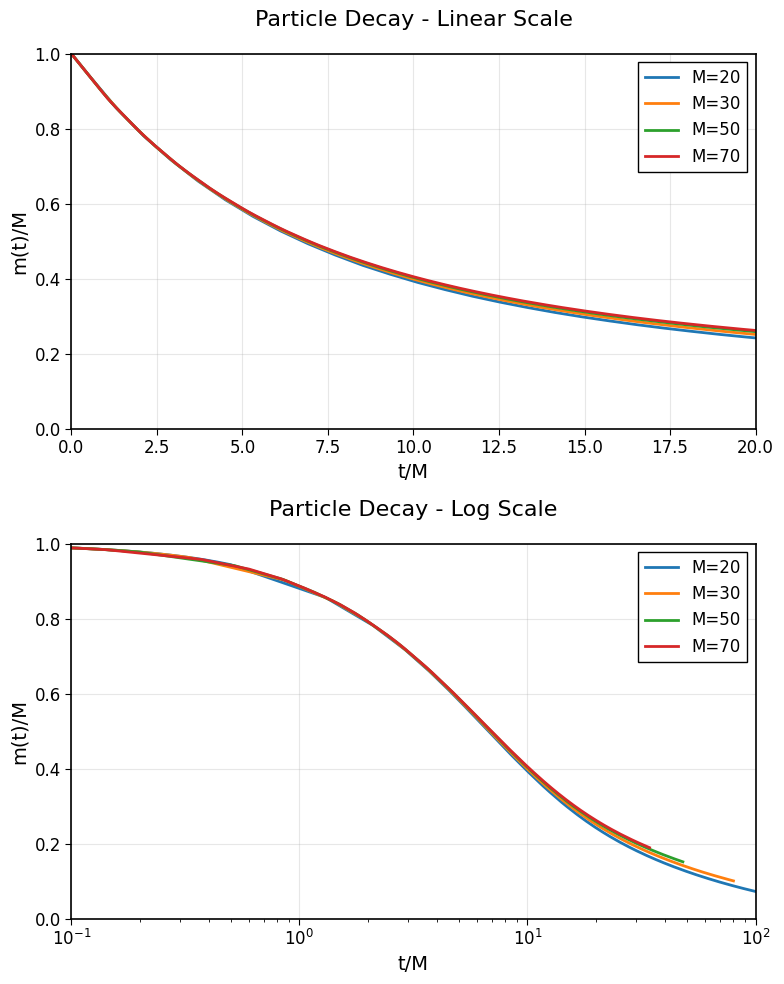

In [5]:
# Thesis Figure 3: Particle decay m(t)/M for M = 20, 30, 50, 70
PageCurveAnalysis.plot_particle_decay_for_different_M()

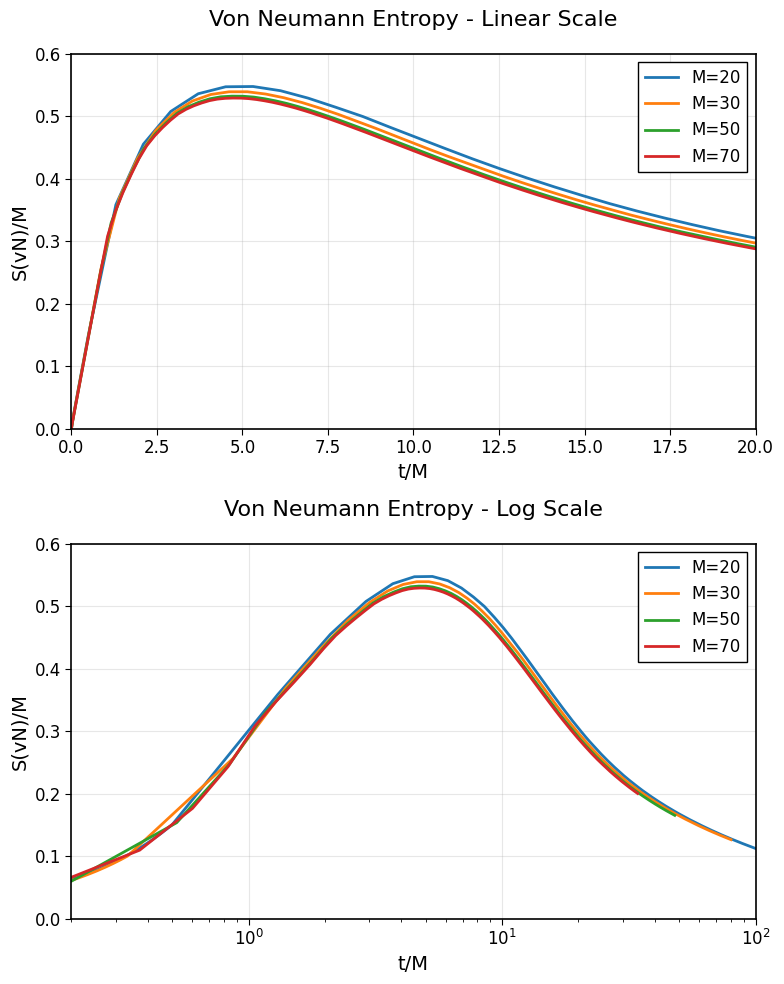

In [8]:
# Thesis Figure 4: Von Neumann entanglement entropy S_vN(t)/M for M = 20, 30, 50, 70
PageCurveAnalysis.von_neumann_entropy_for_different_M()

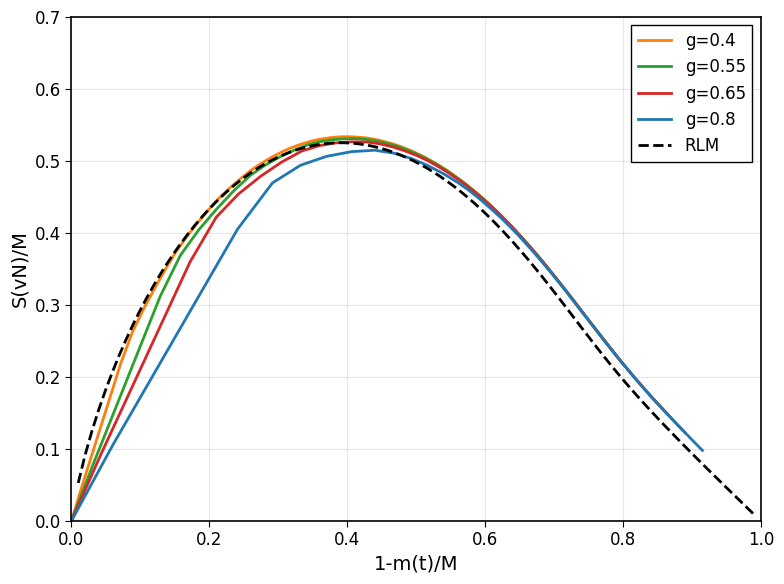

In [9]:
# Thesis Figure 5: Entanglement entropy vs. emitted-particle fraction for g = 0.4, 0.55, 0.65, 0.8
PageCurveAnalysis.von_neumann_entropy_for_different_g()

In [ ]:
PageCurveAnalysis.energy_variance_for_different_g()

Computing energy variance for different g:   0%|          | 0/4 [00:00<?, ?it/s]

Computing energy variance for different g:  75%|███████▌  | 3/4 [15:02<05:01, 301.71s/it]

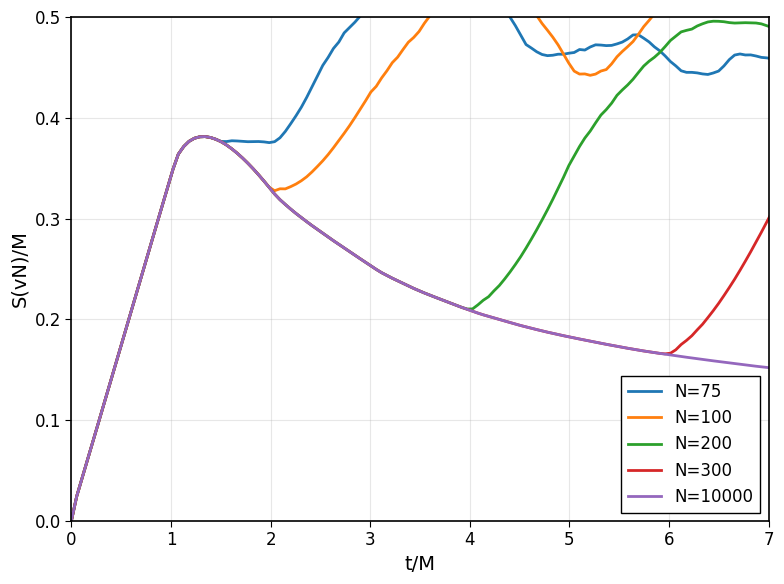

In [ ]:
# Thesis Figure 6: Finite-environment effects on S_vN(t)/M for N = 75, 100, 200, 300, 10000
PageCurveAnalysis.von_neumann_entropy_for_different_N()

In [33]:
def save_publication_figure(fig, filename="fermion_model", format="pdf", dpi=600):
    """
    Save the figure in publication-quality formats
    
    Parameters:
    fig: matplotlib figure
    filename: base filename (without extension)
    format: output format (pdf, eps, png, svg)
    dpi: dots per inch for raster formats
    """
    supported_formats = ["pdf", "eps", "png", "svg"]
    if format not in supported_formats:
        print(f"Format {format} not supported. Using PDF instead.")
        format = "pdf"
    
    # Save with proper settings
    filepath = f"{filename}.{format}"
    if format == "pdf" or format == "eps":
        fig.savefig(filepath, format=format, dpi=dpi, bbox_inches="tight")
    else:
        fig.savefig(filepath, format=format, dpi=dpi, bbox_inches="tight")
    
    print(f"Figure saved as {filepath}")
    return filepath

System labels: ['M', 'M-1', '...', '2', '1']
System_x: [0. 1. 2. 3. 4.]
Environment labels: ['1', '2', '...', 'N']
Env_x: [5. 6. 7. 8. 9.]


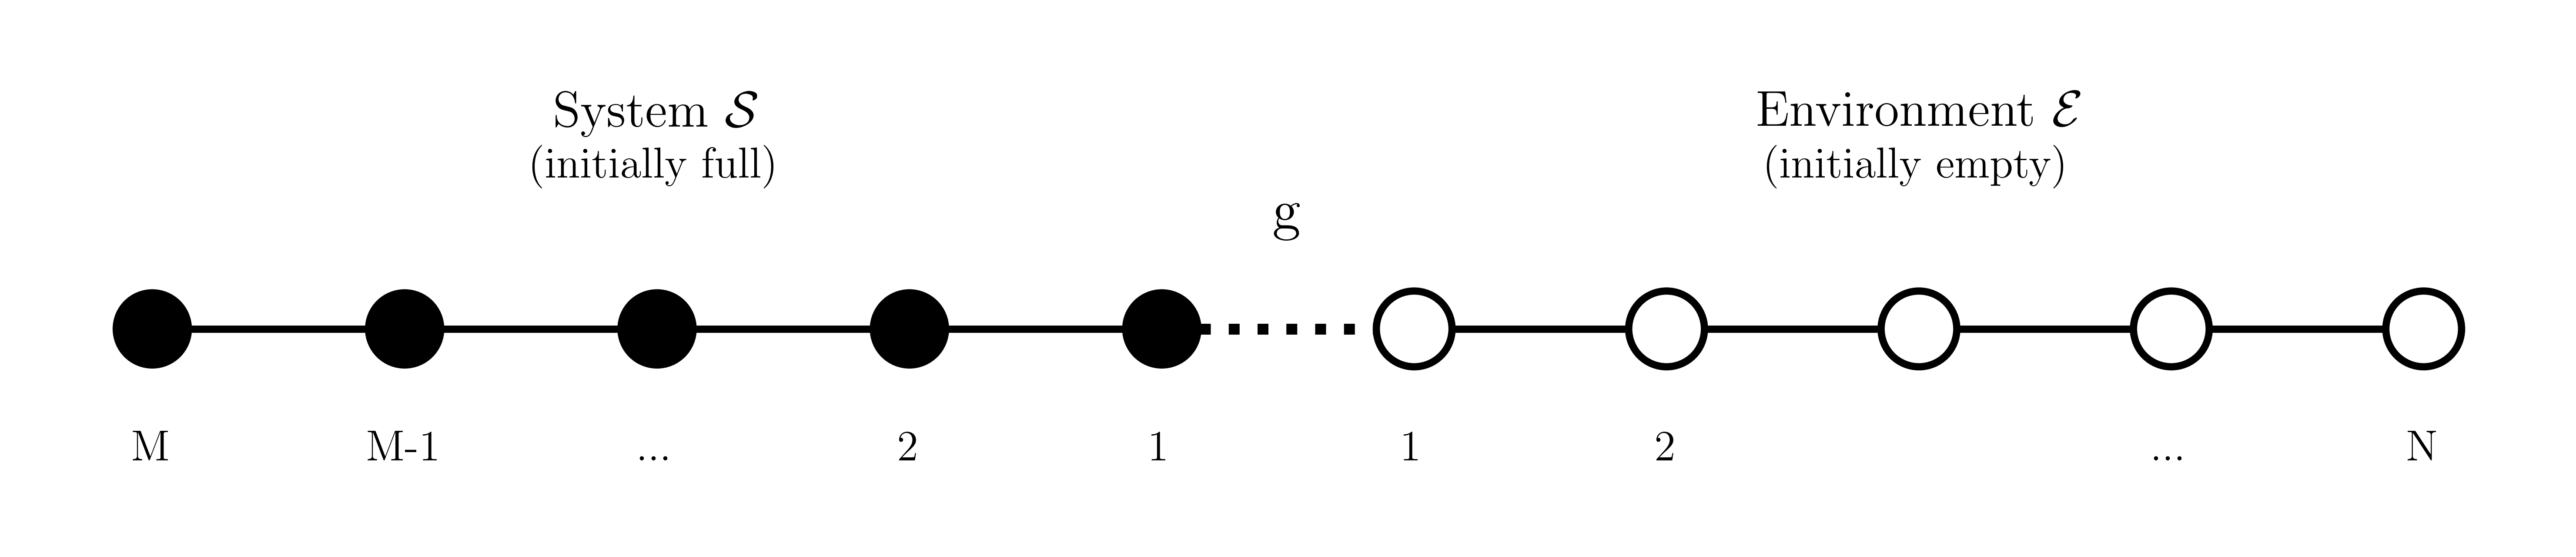

Figure saved as fermion_model_diagram.png
Fermion model schematic diagram created successfully!
Customize M and N parameters to change the number of system and environment sites.


In [39]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

def create_fermion_model_diagram(M=5, N=10, figsize=(10, 3), dpi=600):
    """
    Create a schematic diagram of the one-dimensional free fermion model

    Parameters:
    M (int): Number of system sites
    N (int): Number of environment sites  
    figsize (tuple): Figure size
    """
    # Set up matplotlib to use LaTeX for text rendering if available
    plt.rcParams.update({
        "text.usetex": True,
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman"],
        "mathtext.fontset": "cm",
        "axes.labelsize": 12,
        "font.size": 11,
        "legend.fontsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10
    })
    # Create figure and axis
    fig, ax = plt.subplots(1, 1, figsize=figsize, dpi=dpi)

    # Define positions
    spacing = 1.0

    # System sites positions (filled circles)
    system_x = np.arange(0, M) * spacing
    system_y = np.zeros(M)

    # Environment sites positions (empty circles)
    env_start_x = system_x[-1] + 1 * spacing  # Gap for coupling
    env_x = env_start_x + np.arange(0, N) * spacing
    env_y = np.zeros(N)

    # Plot system sites (filled black circles)
    for i, (x, y) in enumerate(zip(system_x, system_y)):
        circle = plt.Circle((x, y), 0.15, color='black', zorder=3)
        ax.add_patch(circle)

    # Plot environment sites (empty white circles with black edge)
    for i, (x, y) in enumerate(zip(env_x, env_y)):
        circle = plt.Circle((x, y), 0.15, color='white', ec='black', linewidth=2, zorder=3)
        ax.add_patch(circle)

    # Draw connections within system
    for i in range(M-1):
        ax.plot([system_x[i]+0.15, system_x[i+1]-0.15], 
                [system_y[i], system_y[i+1]], 'k-', linewidth=2, zorder=1)

    # Draw connections within environment  
    for i in range(N-1):
        ax.plot([env_x[i]+0.15, env_x[i+1]-0.15], 
                [env_y[i], env_y[i+1]], 'k-', linewidth=2, zorder=1)

    # Draw coupling between system and environment (dotted line)
    coupling_start = system_x[-1] + 0.15
    coupling_end = env_x[0] - 0.15
    ax.plot([coupling_start, coupling_end], [0, 0], 'k:', linewidth=3, zorder=2)

    # Add coupling strength label
    coupling_mid = (coupling_start + coupling_end) / 2
    ax.text(coupling_mid, 0.35, 'g', fontsize=16, ha='center', va='bottom', weight='bold')

   

    # Add site labels
    # System sites (M, M-1, ..., 2, 1)
    system_labels = ['M', 'M-1', '...', '2', '1']
    print("System labels:", system_labels[:M])
    print('System_x:', system_x[:M])
    for i in system_x[:M]:
        if i == 0:
            ax.text(i, -0.4, "M", fontsize=12, ha='center', va='top')
        if i == 1:
            ax.text(i, -0.4, "M-1", fontsize=12, ha='center', va='top')
        if i == 2:
            ax.text(i, -0.4, "...", fontsize=12, ha='center', va='top')
        if i == M-1:
            ax.text(i, -0.4, "1", fontsize=12, ha='center', va='top')
        if i == M-2:
            ax.text(i, -0.4, "2", fontsize=12, ha='center', va='top')

    # Environment sites (1, 2, ..., N)
    env_labels = ['1', '2', '...', 'N']
    print("Environment labels:", env_labels[:N])
    print('Env_x:', env_x[:N])
    for i in env_x[:N]:
        if i == env_x[0]:
            ax.text(i, -0.4, "1", fontsize=12, ha='center', va='top')
        if i == env_x[1]:
            ax.text(i, -0.4, "2", fontsize=12, ha='center', va='top')
        if i == env_x[-1]:
            ax.text(i, -0.4, "N", fontsize=12, ha='center', va='top')
        if i == env_x[-2]:
            ax.text(i, -0.4, "...", fontsize=12, ha='center', va='top')
    
    # Add system and environment labels with descriptions
    system_center = np.mean(system_x)
    env_center = np.mean(env_x)

    ax.text(system_center, 0.8, r'System $\mathcal{S}$', 
            fontsize=14, ha='center', weight='bold')
    ax.text(system_center, 0.6, '(initially full)', 
            fontsize=12, ha='center', style='italic')

    ax.text(env_center, 0.8, r'Environment $\mathcal{E}$', 
            fontsize=14, ha='center', weight='bold') 
    ax.text(env_center, 0.6, '(initially empty)', 
            fontsize=12, ha='center', style='italic')

    # Set axis properties
    ax.set_xlim(-0.5, env_x[-1] + 0.5)
    ax.set_ylim(-0.8, 1.2)
    ax.set_aspect('equal')
    ax.axis('off')

    # Add title
    # plt.title('One-Dimensional Free Fermionic Chain Coupled to Environment', 
    #           fontsize=16, pad=20, weight='bold')

    plt.tight_layout()
    return fig, ax

# Example usage
if __name__ == "__main__":
    # Create the diagram
    fig, ax = create_fermion_model_diagram(M=5, N=5)
    plt.show()

    # Save in publication formats
    # save_publication_figure(fig, "fermion_model_diagram", "pdf")
    save_publication_figure(fig, "fermion_model_diagram", "png", dpi=600)
    print("Fermion model schematic diagram created successfully!")
    print("Customize M and N parameters to change the number of system and environment sites.")

In [35]:
def create_publication_quality_diagram(M=5, N=5, figsize=(10, 3), dpi=300):
    """
    Create a publication-quality diagram of the fermionic system-environment model
    """
    # Create figure with high DPI
    fig, ax = plt.subplots(1, 1, figsize=figsize, dpi=dpi)
    
    # Define positions with better spacing
    spacing = 1.0
    
    # System sites positions (filled circles)
    system_x = np.arange(0, M) * spacing
    system_y = np.zeros(M)
    
    # Environment sites positions (empty circles)
    env_start_x = system_x[-1] + 1.5 * spacing  # Increased gap for coupling
    env_x = env_start_x + np.arange(0, N) * spacing
    env_y = np.zeros(N)
    
    # Plot system sites (filled black circles)
    for i, (x, y) in enumerate(zip(system_x, system_y)):
        circle = plt.Circle((x, y), 0.15, color='black', zorder=3)
        ax.add_patch(circle)
    
    # Plot environment sites (empty white circles with black edge)
    for i, (x, y) in enumerate(zip(env_x, env_y)):
        circle = plt.Circle((x, y), 0.15, color='white', ec='black', linewidth=2, zorder=3)
        ax.add_patch(circle)
    
    # Draw connections within system
    for i in range(M-1):
        ax.plot([system_x[i]+0.15, system_x[i+1]-0.15], 
                [system_y[i], system_y[i+1]], 'k-', linewidth=2, zorder=1)
    
    # Draw connections within environment  
    for i in range(N-1):
        ax.plot([env_x[i]+0.15, env_x[i+1]-0.15], 
                [env_y[i], env_y[i+1]], 'k-', linewidth=2, zorder=1)
    
    # Draw coupling between system and environment (dotted line)
    coupling_start = system_x[-1] + 0.15
    coupling_end = env_x[0] - 0.15
    ax.plot([coupling_start, coupling_end], [0, 0], 'k:', linewidth=3, zorder=2)
    
    # Add coupling strength label
    coupling_mid = (coupling_start + coupling_end) / 2
    ax.text(coupling_mid, 0.35, '$g$', fontsize=16, ha='center', va='bottom', weight='bold')
    
    # Add site labels properly - improved logic
    # System sites (M, M-1, ..., 2, 1)
    if M <= 5:
        # For small systems, label all sites
        for i, x in enumerate(system_x):
            site_num = M - i
            ax.text(x, -0.4, f"{site_num}", fontsize=12, ha='center', va='top')
    else:
        # For larger systems, label first, last and middle with ellipsis
        ax.text(system_x[0], -0.4, f"{M}", fontsize=12, ha='center', va='top')
        ax.text(system_x[1], -0.4, f"{M-1}", fontsize=12, ha='center', va='top')
        ax.text(system_x[M//2], -0.4, "...", fontsize=12, ha='center', va='top')
        ax.text(system_x[-2], -0.4, "2", fontsize=12, ha='center', va='top')
        ax.text(system_x[-1], -0.4, "1", fontsize=12, ha='center', va='top')
    
    # Environment sites (1, 2, ..., N)
    if N <= 5:
        # For small environments, label all sites
        for i, x in enumerate(env_x):
            site_num = i + 1
            ax.text(x, -0.4, f"{site_num}", fontsize=12, ha='center', va='top')
    else:
        # For larger environments, label first, second, last and second-to-last
        ax.text(env_x[0], -0.4, "1", fontsize=12, ha='center', va='top')
        ax.text(env_x[1], -0.4, "2", fontsize=12, ha='center', va='top')
        ax.text(env_x[N//2], -0.4, "...", fontsize=12, ha='center', va='top')
        ax.text(env_x[-1], -0.4, f"{N}", fontsize=12, ha='center', va='top')
    
    # Add system and environment labels with descriptions - using LaTeX for math symbols
    system_center = np.mean(system_x)
    env_center = np.mean(env_x)
    
    ax.text(system_center, 0.8, r'System $\mathcal{S}$', 
            fontsize=14, ha='center', weight='bold')
    ax.text(system_center, 0.5, '(initially full)', 
            fontsize=12, ha='center', style='italic')
    
    ax.text(env_center, 0.8, r'Environment $\mathcal{E}$', 
            fontsize=14, ha='center', weight='bold') 
    ax.text(env_center, 0.5, '(initially empty)', 
            fontsize=12, ha='center', style='italic')
    
    # Set axis properties
    ax.set_xlim(-0.8, env_x[-1] + 0.8)
    ax.set_ylim(-0.8, 1.2)
    ax.set_aspect('equal')
    ax.axis('off')
    
    # Add title
    plt.title('One-Dimensional Free Fermion Model: System-Environment Coupling', 
              fontsize=16, pad=20, weight='bold')
    
    plt.tight_layout()
    return fig, ax

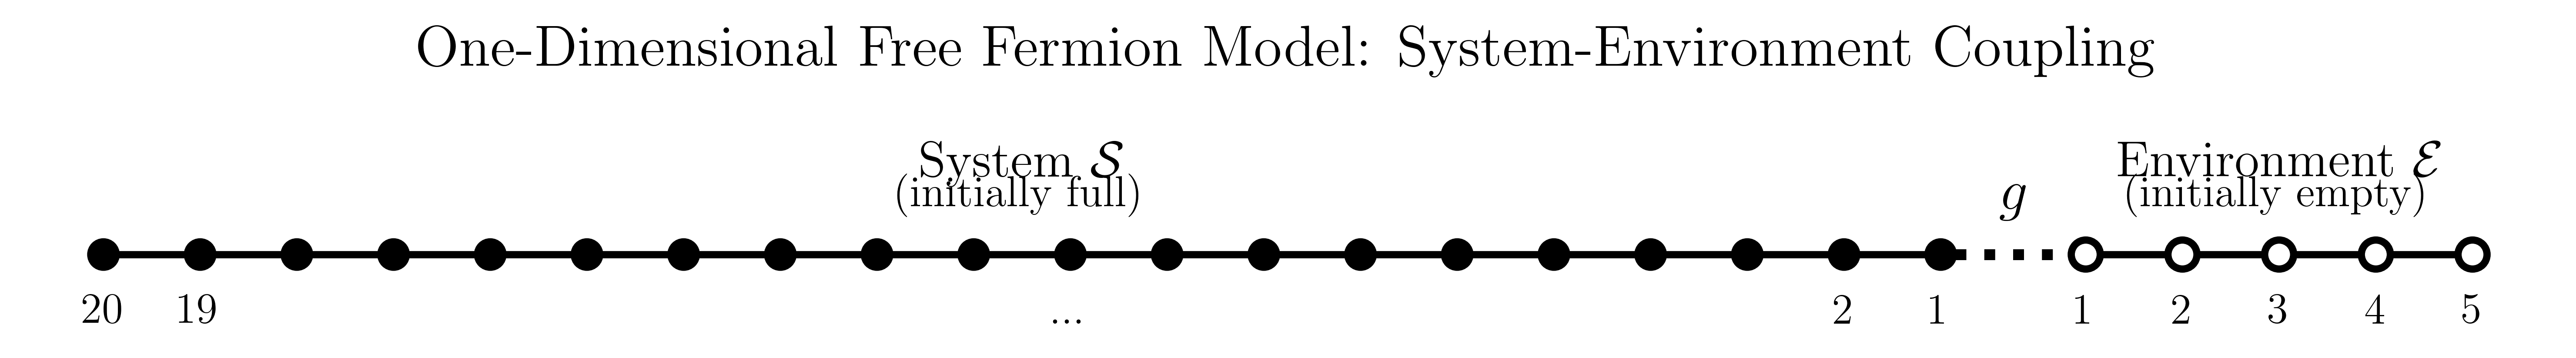

Figure saved as fermion_model_diagram.pdf
Figure saved as fermion_model_diagram.png


'fermion_model_diagram.png'

In [ ]:
# # Create high-quality publication diagram
# fig, ax = create_publication_quality_diagram(M=20, N=5, figsize=(10, 3), dpi=600)

# # Show it in the notebook
# plt.show()

# # Save in publication formats
# save_publication_figure(fig, "fermion_model_diagram", "pdf")
# save_publication_figure(fig, "fermion_model_diagram", "png", dpi=600)

## Page Curve Conceptual Schematic

The following cell creates a conceptual diagram showing how the effective Hilbert space shrinks over time during the Page curve dynamics.

In [ ]:
def create_page_curve_schematic(figsize=(10, 7), dpi=300):
    """
    Create high-quality schematic showing nested regions representing effective Hilbert space evolution
    This reproduces the conceptual diagram showing the Page curve dynamics with better visual clarity
    """
    # Set up matplotlib for LaTeX rendering
    try:
        plt.rcParams.update({
            "text.usetex": True,
            "font.family": "serif",
            "font.serif": ["Computer Modern Roman"],
            "mathtext.fontset": "cm",
        })
    except:
        plt.rcParams.update({"font.family": "serif"})
    
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    
    ax.set_xlim(-4, 4)
    ax.set_ylim(-3, 3)
    ax.set_aspect('equal')
    ax.axis('off')
    
    from matplotlib.patches import Ellipse
    
    # Outermost hatched ellipse (slightly lighter hatch and stroke)
    outer = Ellipse((0, 0), 7.0, 5.0,
                    facecolor='white', edgecolor='#9C9C9C', linewidth=1.2,
                    hatch='///', alpha=0.42, zorder=1)
    ax.add_patch(outer)
    
    # Inner gradient ellipses (slightly lighter tones and spacing)
    mid1 = Ellipse((0, 0), 5.2, 3.7, facecolor='#E8E8E8', edgecolor='#B5B5B5', linewidth=1.8, zorder=2)
    ax.add_patch(mid1)
    mid2 = Ellipse((0, 0), 3.8, 2.7, facecolor='#BBBBBB', edgecolor='#7A7A7A', linewidth=2.0, zorder=3)
    ax.add_patch(mid2)
    mid3 = Ellipse((0, 0), 2.6, 1.80, facecolor='#8C8C8C', edgecolor='#4A4A4A', linewidth=2.0, zorder=4)
    ax.add_patch(mid3)
    
    # Final effective Hilbert space
    final = Ellipse((1.15, 0.05), 1.05, 0.62, facecolor='black', edgecolor='black', linewidth=2.5, zorder=5)
    ax.add_patch(final)
    
    # Initial state separate ellipse (kept clearly outside)
    initial_ellipse = Ellipse((-2.10, 0.55), 0.8, 0.5,
                              facecolor='white', edgecolor='#0066CC', linewidth=3,
                              zorder=10)
    ax.add_patch(initial_ellipse)
    
    # Initial state label (blue)
    ax.text(-2.10, 0.55, r'$|\\Phi_{\\mathrm{sys}}(0)\\rangle$', fontsize=11,
            ha='center', va='center', color='#0066CC', weight='bold', zorder=11)
    
    # Final state label (white on black)
    ax.text(1.15, 0.05, r'$\\mathcal{H}^{\\mathrm{eff}}_{\\mathrm{S}}(\\infty)$', fontsize=10,
            ha='center', va='center', color='white', weight='bold', zorder=6)
    
    # Evolution arrow (end point on tangent near left-upper of final ellipse)
    arrow_props = dict(arrowstyle='->', lw=3.5, color='#FF0000',
                       connectionstyle="arc3,rad=0.10", mutation_scale=24)
    # Start near initial state; end on boundary of final ellipse (~(0.65, 0.14))
    ax.annotate('', xy=(0.65, 0.14), xytext=(-1.55, 0.52), arrowprops=arrow_props, zorder=12)
    
    # rho_sys(t_P) label lower-left on hatched region
    ax.text(-2.30, -2.05, r'$\\rho_{\\mathrm{sys}}(t_P)$', fontsize=14,
            ha='center', va='center', style='italic', color='#303030', zorder=2)
    
    # Full system Hilbert space label top-right
    ax.text(3.15, 1.95, r'$\\mathcal{H}_{\\mathrm{sys}}$', fontsize=16,
            ha='center', va='center', weight='bold', zorder=2)
    
    plt.tight_layout()
    return fig, ax

Page curve schematic saved as page_curve_schematic.png/pdf


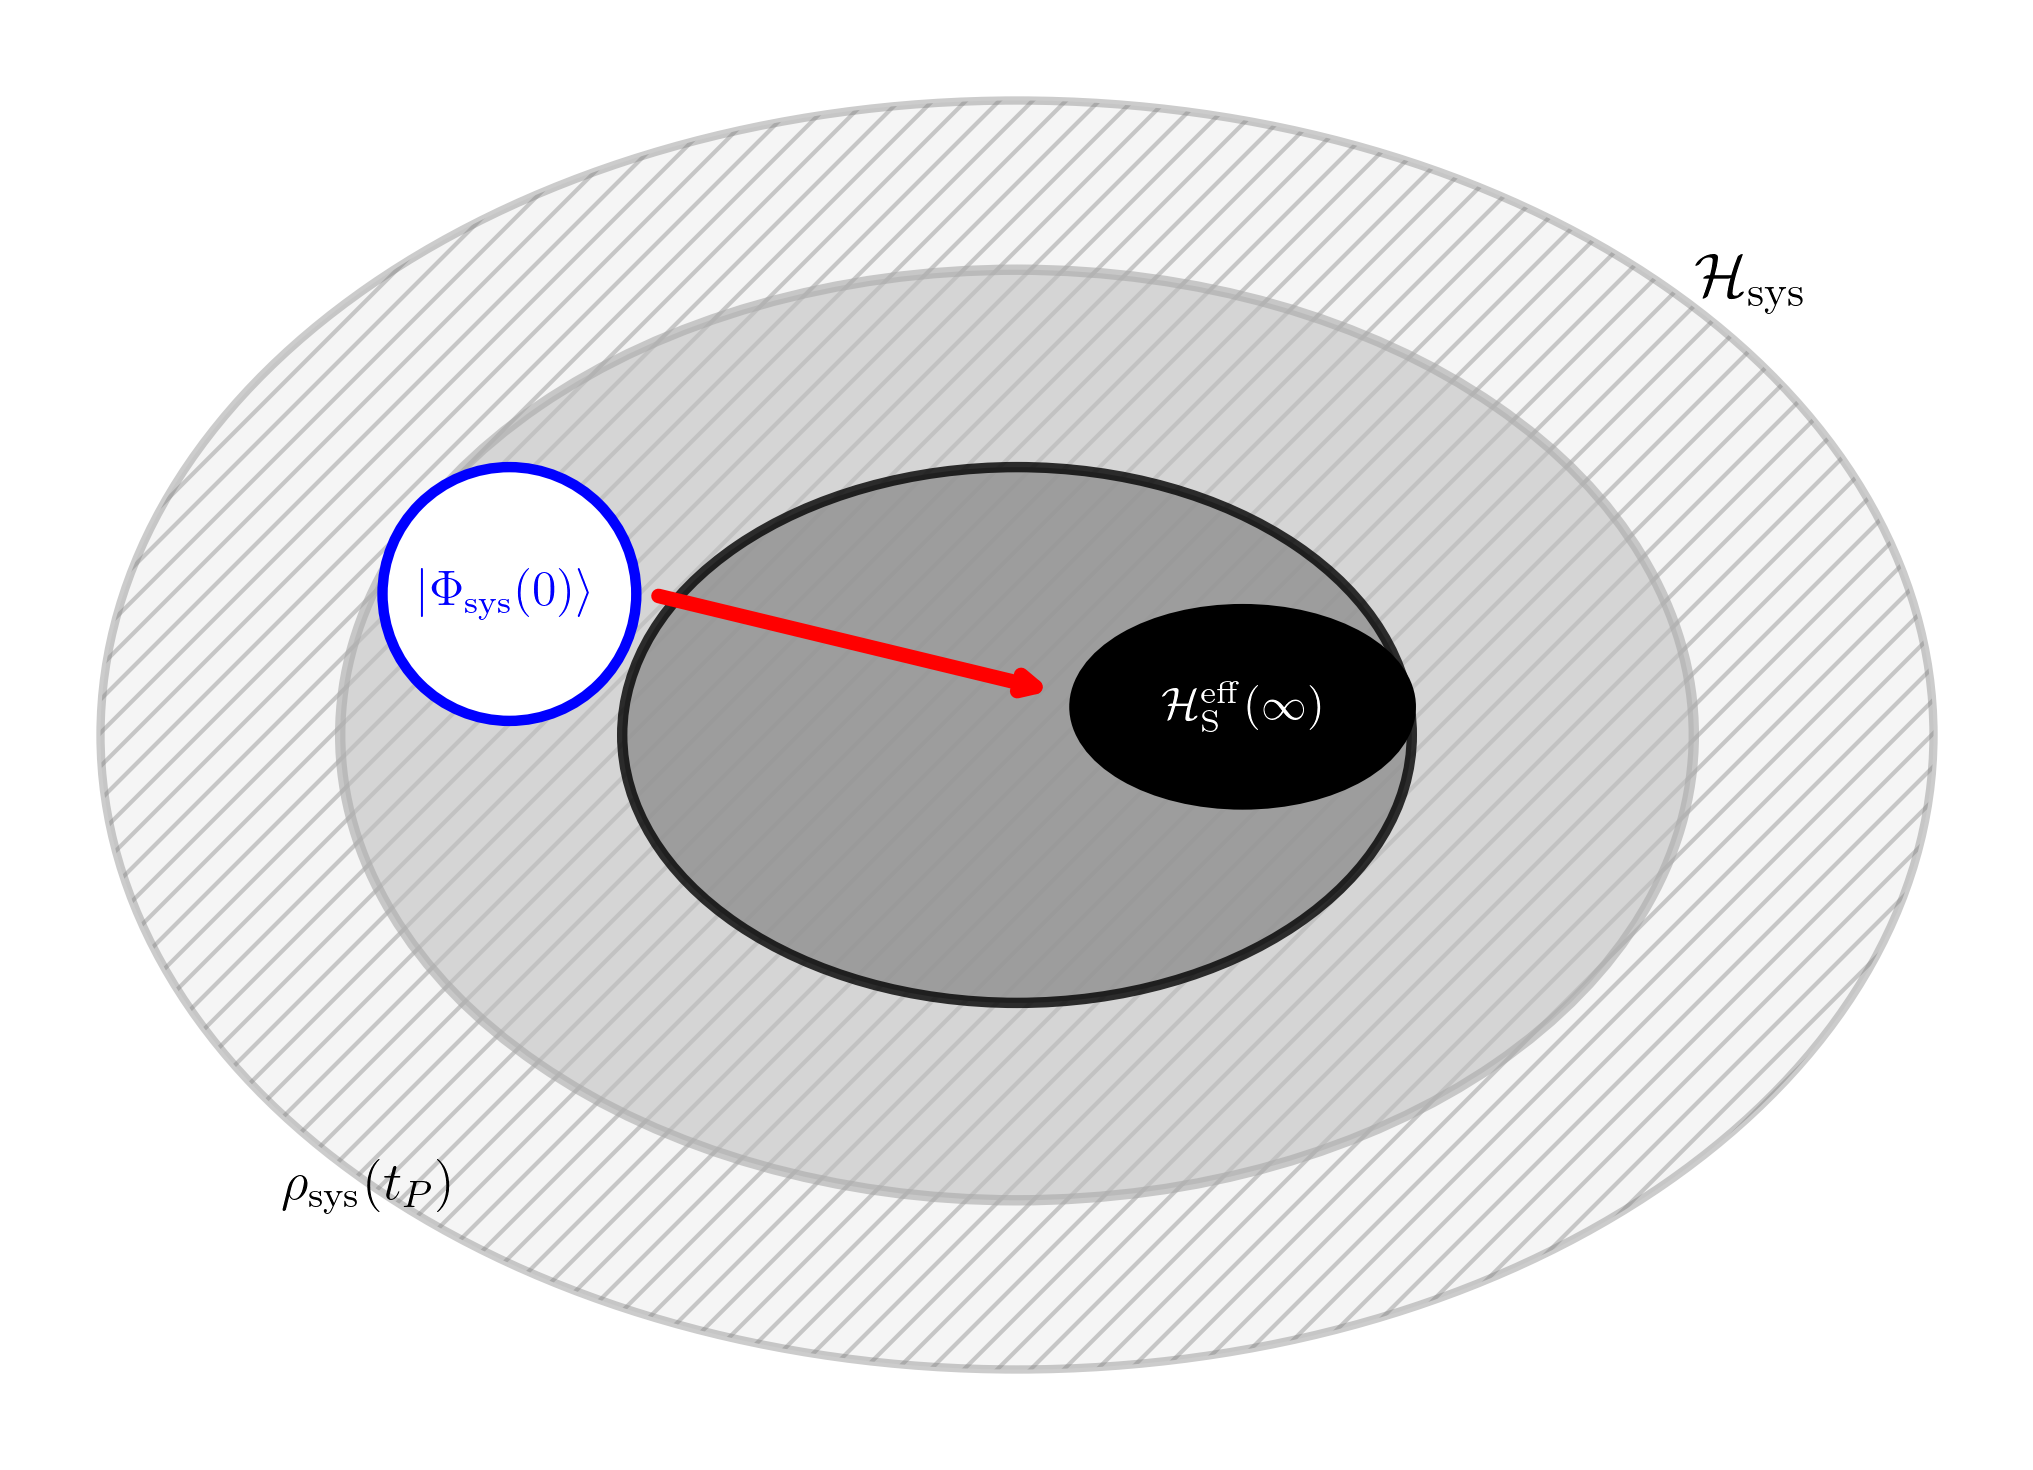

In [14]:
# Create and display the Page curve schematic
fig_schematic, ax_schematic = create_page_curve_schematic(dpi=300)
fig_schematic.savefig('page_curve_schematic.png', dpi=300, bbox_inches='tight')
fig_schematic.savefig('page_curve_schematic.pdf', bbox_inches='tight')
print("Page curve schematic saved as page_curve_schematic.png/pdf")
plt.show()